# Praktikum 9 — Fuzzy System Sederhana untuk Pengaturan Kecepatan Kipas

**Mata Kuliah:** Kecerdasan Buatan (RPL3404) · **D4 Teknologi Rekayasa Perangkat Lunak**
**Jurusan Teknologi Informasi — Politeknik Negeri Padang** · Buku Ajar Bab 9: *Pengenalan Fuzzy System*

| Identitas | Isian |
|---|---|
| Nama | Windi Sri Rahayu |
| NIM | 2611089002 |
| Kelas | TRPL AK 1|
| Tanggal praktikum | 01 november 2026|
| Tautan repositori Git | https://github.com/windyrahayu45/Kecerdasan-Buatan|


> Jalankan sel secara berurutan dari atas ke bawah. Notebook ini hanya memakai pustaka standar Python
> (`math`); `matplotlib` dipakai untuk menggambar dan bersifat opsional — bila tidak tersedia, seluruh
> perhitungan tetap berjalan. **Tidak ada bilangan acak sama sekali**, sehingga angka yang Anda peroleh
> harus sama persis dengan angka pada Buku Ajar.
>
> Pustaka fuzzy siap pakai sengaja **tidak** dipakai. Yang sedang dipelajari justru isi dari pustaka
> semacam itu.

## A. Tujuan Praktikum

1. Menuliskan fungsi keanggotaan segitiga, trapesium, dan Gauss sebagai program.
2. Membedakan perilaku himpunan tegas (crisp set) dan himpunan fuzzy pada kasus yang sama.
3. Menerapkan operator fuzzy (komplemen, t-norm, s-norm) dan hedge.
4. Membangun variabel linguistik beserta basis aturannya.
5. Menjalankan ketiga tahap penalaran fuzzy — fuzzifikasi, inferensi Mamdani, dan defuzzifikasi.
6. Menghitung keluaran defuzzifikasi dengan metode titik berat (centroid) pada domain diskret.
7. Membandingkan perilaku sistem fuzzy dengan sistem beraturan tegas.

## B. Persiapan

Periksa versi Python dan ketersediaan `matplotlib`. Sel ini tidak boleh gagal walaupun `matplotlib`
belum terpasang.

In [1]:
import math
import sys

print("Python:", sys.version.split()[0])

try:
    import matplotlib
    matplotlib.use("Agg") if "ipykernel" not in sys.modules else None
    import matplotlib.pyplot as plt
    GAMBAR = True
    print("matplotlib tersedia — sel penggambaran akan dijalankan.")
except ImportError:
    GAMBAR = False
    print("matplotlib tidak tersedia — sel penggambaran akan dilewati.")


def baris(*sel, lebar=14):
    """Pembantu pencetakan tabel agar kolomnya rata."""
    print("".join(str(s).ljust(lebar) for s in sel).rstrip())

Python: 3.13.3


matplotlib tersedia — sel penggambaran akan dijalankan.


## C. Langkah 1 — Fungsi Keanggotaan

Fungsi keanggotaan memetakan domain $X$ ke selang $[0,1]$:

$$\mu_A : X \rightarrow [0,1]$$

Tiga syarat yang harus dipenuhi (Engelbrecht, 2007, Subbab 20.2):

1. nilainya tidak boleh kurang dari 0 dan tidak boleh lebih dari 1;
2. jangkauannya tepat $[0,1]$;
3. setiap $x$ hanya boleh memiliki **satu** nilai keanggotaan.

Jalankan sel berikut, lalu **perhatikan urutan pemeriksaan pada `trapesium`**: bagian datar diperiksa
lebih dahulu agar bentuk *bahu* (ketika $a=b$ atau $c=d$) tetap bernilai 1 di ujung domain.

In [2]:
def segitiga(x, a, b, c):
    """Fungsi keanggotaan segitiga: naik dari a ke b, turun dari b ke c."""
    if x <= a or x >= c:
        return 0.0
    if x == b:
        return 1.0
    if x < b:
        return (x - a) / (b - a)
    return (c - x) / (c - b)


def trapesium(x, a, b, c, d):
    """Fungsi keanggotaan trapesium: naik a→b, datar b→c, turun c→d.

    Bagian datar diperiksa lebih dahulu agar bentuk bahu (a = b, atau
    c = d) tetap bernilai 1 di ujung domain.
    """
    if b <= x <= c:
        return 1.0
    if x <= a or x >= d:
        return 0.0
    if x < b:
        return (x - a) / (b - a)
    return (d - x) / (d - c)


def gauss(x, beta, gamma):
    """Fungsi keanggotaan Gauss: mu(x) = e^(-gamma (x - beta)^2)."""
    return math.exp(-gamma * (x - beta) ** 2)

Bandingkan ketiga bentuk pada titik yang sama. Perhatikan kolom Gauss pada nilai $x$ yang jauh dari
puncak: nilainya **tidak pernah benar-benar nol**, hanya mengecil terus-menerus.

In [3]:
baris("x", "Segitiga", "Trapesium", "Gauss", lebar=12)
print("-" * 48)
for x in range(20, 36):
    baris(x,
          f"{segitiga(x, 22, 27, 32):.2f}",
          f"{trapesium(x, 22, 26, 28, 32):.2f}",
          f"{gauss(x, 27, 0.08):.2f}", lebar=12)

x           Segitiga    Trapesium   Gauss
------------------------------------------------
20          0.00        0.00        0.02
21          0.00        0.00        0.06
22          0.00        0.00        0.14
23          0.20        0.25        0.28
24          0.40        0.50        0.49
25          0.60        0.75        0.73
26          0.80        1.00        0.92
27          1.00        1.00        1.00
28          0.80        1.00        0.92
29          0.60        0.75        0.73
30          0.40        0.50        0.49
31          0.20        0.25        0.28
32          0.00        0.00        0.14
33          0.00        0.00        0.06
34          0.00        0.00        0.02
35          0.00        0.00        0.01


### Pertanyaan 1
Ubahlah parameter `trapesium(22, 26, 28, 32)` menjadi `trapesium(22, 22, 28, 32)` lalu jalankan ulang.
Apa yang terjadi pada nilai di $x = 22$, dan mengapa? Kaitkan jawaban Anda dengan urutan pemeriksaan di
dalam fungsi tersebut.

In [4]:
nilai_bahu = trapesium(22, 22, 22, 28, 32)
print(f"trapesium(x=22, a=22, b=22, c=28, d=32) = {nilai_bahu:.1f}")
print("Nilainya 1 karena x = 22 termasuk bagian datar b <= x <= c.")
print("Bagian datar diperiksa sebelum x <= a, sehingga bahu kiri tetap bernilai 1.")

trapesium(x=22, a=22, b=22, c=28, d=32) = 1.0
Nilainya 1 karena x = 22 termasuk bagian datar b <= x <= c.
Bagian datar diperiksa sebelum x <= a, sehingga bahu kiri tetap bernilai 1.


## D. Langkah 2 — Himpunan Tegas Dibandingkan Himpunan Fuzzy

Contoh berikut diambil langsung dari Engelbrecht (2007, Persamaan 20.5), yaitu himpunan **orang tinggi**
dengan satuan meter:

$$
tinggi(x) = \begin{cases}
0 & x < 1{,}5 \\
(x - 1{,}5) \times 2{,}0 & 1{,}5 \le x \le 2{,}0 \\
1 & x > 2{,}0
\end{cases}
$$

In [5]:
def tinggi(x):
    """Contoh dari Engelbrecht (2007), Persamaan 20.5 — himpunan 'tinggi'.

    Satuan x adalah meter.
        0                       bila x < 1,5
        (x - 1,5) x 2,0         bila 1,5 <= x <= 2,0
        1                       bila x > 2,0
    """
    if x < 1.5:
        return 0.0
    if x > 2.0:
        return 1.0
    return (x - 1.5) * 2.0


def crisp_tinggi(x, batas=1.75):
    """Himpunan tegas 'tinggi': hanya mengenal anggota atau bukan anggota."""
    return 1.0 if x >= batas else 0.0

In [6]:
baris("Tinggi (m)", "Crisp", "Fuzzy")
print("-" * 42)
for x in (1.50, 1.60, 1.70, 1.74, 1.75, 1.76, 1.80, 1.90, 2.00, 2.10):
    baris(f"{x:.2f}", f"{crisp_tinggi(x):.0f}", f"{tinggi(x):.2f}")

print()
print(f"crisp: 1,74 m -> {crisp_tinggi(1.74):.0f}, 1,76 m -> {crisp_tinggi(1.76):.0f}  (melompat)")
print(f"fuzzy: 1,74 m -> {tinggi(1.74):.2f}, 1,76 m -> {tinggi(1.76):.2f}  (berubah sedikit)")

Tinggi (m)    Crisp         Fuzzy
------------------------------------------
1.50          0             0.00
1.60          0             0.20
1.70          0             0.40
1.74          0             0.48
1.75          1             0.50
1.76          1             0.52
1.80          1             0.60
1.90          1             0.80
2.00          1             1.00
2.10          1             1.00

crisp: 1,74 m -> 0, 1,76 m -> 1  (melompat)
fuzzy: 1,74 m -> 0.48, 1,76 m -> 0.52  (berubah sedikit)


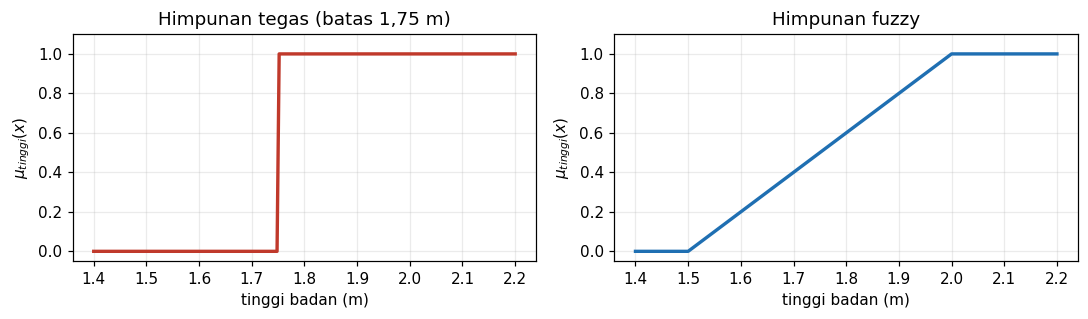

In [7]:
if GAMBAR:
    x = [1.4 + 0.004 * i for i in range(201)]
    fig, axs = plt.subplots(1, 2, figsize=(10, 3), dpi=110)
    axs[0].plot(x, [crisp_tinggi(v) for v in x], color="#C0392B", lw=2.2)
    axs[0].set_title("Himpunan tegas (batas 1,75 m)")
    axs[1].plot(x, [tinggi(v) for v in x], color="#1F6FB2", lw=2.2)
    axs[1].set_title("Himpunan fuzzy")
    for ax in axs:
        ax.set_xlabel("tinggi badan (m)"); ax.set_ylabel(r"$\mu_{tinggi}(x)$")
        ax.set_ylim(-0.05, 1.1); ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()

### Pertanyaan 2
Seseorang setinggi 1,75 m memperoleh derajat keanggotaan tepat 0,50. Jelaskan mengapa angka itu masuk
akal, lalu sebutkan satu keadaan nyata di mana batas **tegas** justru lebih baik daripada derajat
keanggotaan.

In [8]:
mu_tinggi_175 = tinggi(1.75)
print(f"mu_tinggi(1,75 m) = {mu_tinggi_175:.2f}")
print("Nilai 0,50 masuk akal: 1,75 m berada tepat di tengah rentang transisi 1,50-2,00 m.")
print("Batas tegas lebih tepat untuk keputusan administratif yang wajib memenuhi syarat minimum, misalnya batas tinggi keselamatan pada wahana.")

mu_tinggi(1,75 m) = 0.50
Nilai 0,50 masuk akal: 1,75 m berada tepat di tengah rentang transisi 1,50-2,00 m.
Batas tegas lebih tepat untuk keputusan administratif yang wajib memenuhi syarat minimum, misalnya batas tinggi keselamatan pada wahana.


## E. Langkah 3 — Operator Fuzzy, Hedge, dan Kardinalitas

Operator irisan disebut **t-norm** dan operator gabungan disebut **s-norm**. Dua yang paling lazim adalah
`min`/`max`. Hedge seperti *sangat* dan *agak* mengubah derajat keanggotaan secara sistematis.

In [9]:
# ---- Langkah 2: operator fuzzy ------------------------------------------
# Operator dasar pada himpunan fuzzy (Engelbrecht, 2007, Subbab 20.3).
# Irisan memakai t-norm, gabungan memakai s-norm. Dua yang paling lazim
# adalah min dan max.

def komplemen(mu):
    """NOT: mu_notA(x) = 1 - mu_A(x)."""
    return 1.0 - mu


def irisan_min(mu1, mu2):
    """AND dengan min-operator."""
    return min(mu1, mu2)


def irisan_hasilkali(mu1, mu2):
    """AND dengan product-operator; hasilnya selalu <= min-operator."""
    return mu1 * mu2


def gabungan_max(mu1, mu2):
    """OR dengan max-operator."""
    return max(mu1, mu2)


def gabungan_jumlah(mu1, mu2):
    """OR dengan summation-operator: mu1 + mu2 - mu1 mu2."""
    return mu1 + mu2 - mu1 * mu2


def sangat(mu):
    """Hedge pemusatan 'sangat': mu^2 (Engelbrecht, 2007, Persamaan 21.1)."""
    return mu ** 2


def agak(mu):
    """Hedge pelebaran 'agak': akar mu (Engelbrecht, 2007, Persamaan 21.2)."""
    return math.sqrt(mu)


def kardinalitas(himpunan):
    """card(A) = jumlah seluruh derajat keanggotaan (Persamaan 20.19)."""
    return sum(himpunan.values())

Contoh berikut berasal dari Engelbrecht (2007, Bab 21): siapa pemain basket yang lebih baik, Peter atau
Carl? Aturannya: *pemain basket yang baik adalah orang yang **tinggi** **dan** atlet yang baik*.

In [10]:
print("Diketahui  tinggi(Peter) = 0,9  dan  atlet_baik(Peter) = 0,8")
print("           tinggi(Carl)  = 0,9  dan  atlet_baik(Carl)  = 0,5")
print()
for nama, mt, ma in (("Peter", 0.9, 0.8), ("Carl", 0.9, 0.5)):
    print(f"   min({mt}, {ma}) = {irisan_min(mt, ma):.1f}   -> {nama}")

print()
print("Perbandingan t-norm dan s-norm untuk mu_A = 0,9 dan mu_B = 0,5:")
baris("Operator", "Hasil", lebar=22)
print("-" * 34)
baris("min (AND)", f"{irisan_min(0.9, 0.5):.2f}", lebar=22)
baris("hasil kali (AND)", f"{irisan_hasilkali(0.9, 0.5):.2f}", lebar=22)
baris("max (OR)", f"{gabungan_max(0.9, 0.5):.2f}", lebar=22)
baris("jumlah (OR)", f"{gabungan_jumlah(0.9, 0.5):.2f}", lebar=22)
baris("komplemen A (NOT)", f"{komplemen(0.9):.2f}", lebar=22)

print()
print("Hedge:")
print(f"   tinggi(Peter)           = 0,90")
print(f"   sangat tinggi  = 0,90^2 = {sangat(0.9):.2f}")
print(f"   agak tinggi    = akar 0,81 = {agak(0.81):.2f}")

A = {"a": 0.3, "b": 0.9, "c": 0.1, "d": 0.7}
print()
print(f"card(A) untuk A = 0,3/a + 0,9/b + 0,1/c + 0,7/d  ->  {kardinalitas(A):.1f}")

Diketahui  tinggi(Peter) = 0,9  dan  atlet_baik(Peter) = 0,8
           tinggi(Carl)  = 0,9  dan  atlet_baik(Carl)  = 0,5

   min(0.9, 0.8) = 0.8   -> Peter
   min(0.9, 0.5) = 0.5   -> Carl

Perbandingan t-norm dan s-norm untuk mu_A = 0,9 dan mu_B = 0,5:
Operator              Hasil
----------------------------------
min (AND)             0.50
hasil kali (AND)      0.45
max (OR)              0.90
jumlah (OR)           0.95
komplemen A (NOT)     0.10

Hedge:
   tinggi(Peter)           = 0,90
   sangat tinggi  = 0,90^2 = 0.81
   agak tinggi    = akar 0,81 = 0.90

card(A) untuk A = 0,3/a + 0,9/b + 0,1/c + 0,7/d  ->  2.0


### Pertanyaan 3
Mengapa operator hasil kali disebut lebih "keras" daripada `min`? Buktikan dengan tiga pasang nilai
pilihan Anda sendiri, lalu jelaskan apa yang terjadi pada rangkaian irisan yang panjang.

In [11]:
pasangan = ((0.9, 0.8), (0.7, 0.6), (0.4, 0.3))
baris("mu_A", "mu_B", "min", "hasil kali", lebar=14)
print("-" * 56)
for mu_a, mu_b in pasangan:
    print(f"{mu_a:<14.2f}{mu_b:<14.2f}{irisan_min(mu_a, mu_b):<14.2f}{irisan_hasilkali(mu_a, mu_b):.2f}")
print("Untuk derajat di dalam (0, 1), hasil kali tidak melebihi min dan biasanya lebih kecil.")
print("Pada banyak anteseden, hasil kali berulang terus mengecilkan firing strength; aturan dengan banyak syarat menjadi makin sulit menyala kuat.")

mu_A          mu_B          min           hasil kali
--------------------------------------------------------
0.90          0.80          0.80          0.72
0.70          0.60          0.60          0.42
0.40          0.30          0.30          0.12
Untuk derajat di dalam (0, 1), hasil kali tidak melebihi min dan biasanya lebih kecil.
Pada banyak anteseden, hasil kali berulang terus mengecilkan firing strength; aturan dengan banyak syarat menjadi makin sulit menyala kuat.


## F. Langkah 4 — Variabel Linguistik dan Basis Aturan

Inilah seluruh **basis pengetahuan** sistem: dua kamus dan satu daftar. Pengetahuan berada di luar mesin
inferensinya, persis seperti pada sistem pakar berbasis aturan.

| Variabel | Himpunan fuzzy | Bentuk dan parameter |
|---|---|---|
| SUHU (°C) | DINGIN | Trapesium (10, 10, 18, 24) |
| | HANGAT | Segitiga (20, 27, 32) |
| | PANAS | Trapesium (27, 32, 40, 40) |
| KECEPATAN KIPAS (%) | LAMBAT | Trapesium (0, 0, 10, 40) |
| | SEDANG | Segitiga (20, 50, 80) |
| | CEPAT | Trapesium (60, 90, 100, 100) |

In [12]:
# ---- Langkah 3: variabel linguistik -------------------------------------
# Satu variabel linguistik memiliki beberapa himpunan fuzzy sebagai
# nilainya. Di sini: SUHU (masukan) dan KECEPATAN KIPAS (keluaran).

SUHU = {
    'DINGIN': lambda x: trapesium(x, 10.0, 10.0, 18.0, 24.0),
    'HANGAT': lambda x: segitiga(x, 20.0, 27.0, 32.0),
    'PANAS':  lambda x: trapesium(x, 27.0, 32.0, 40.0, 40.0),
}

KIPAS = {
    'LAMBAT': lambda y: trapesium(y, 0.0, 0.0, 10.0, 40.0),
    'SEDANG': lambda y: segitiga(y, 20.0, 50.0, 80.0),
    'CEPAT':  lambda y: trapesium(y, 60.0, 90.0, 100.0, 100.0),
}

# ---- Langkah 4: basis aturan fuzzy --------------------------------------
# Bentuk umum: JIKA anteseden MAKA konsekuen.
# Untuk kasus paling sederhana, setiap aturan hanya memiliki satu anteseden.

ATURAN = [
    ('R1', 'DINGIN', 'LAMBAT'),
    ('R2', 'HANGAT', 'SEDANG'),
    ('R3', 'PANAS',  'CEPAT'),
]

DOMAIN_KIPAS = [float(y) for y in range(0, 101)]   # 0..100 persen, langkah 1

In [13]:
print("Variabel SUHU:")
baris("Suhu", "DINGIN", "HANGAT", "PANAS", lebar=12)
print("-" * 48)
for x in range(16, 37, 2):
    baris(x, f"{SUHU['DINGIN'](x):.2f}", f"{SUHU['HANGAT'](x):.2f}",
          f"{SUHU['PANAS'](x):.2f}", lebar=12)

print()
print("Variabel KECEPATAN KIPAS:")
baris("Kecepatan", "LAMBAT", "SEDANG", "CEPAT", lebar=12)
print("-" * 48)
for y in range(0, 101, 10):
    baris(y, f"{KIPAS['LAMBAT'](y):.2f}", f"{KIPAS['SEDANG'](y):.2f}",
          f"{KIPAS['CEPAT'](y):.2f}", lebar=12)

Variabel SUHU:
Suhu        DINGIN      HANGAT      PANAS
------------------------------------------------
16          1.00        0.00        0.00
18          1.00        0.00        0.00
20          0.67        0.00        0.00
22          0.33        0.29        0.00
24          0.00        0.57        0.00
26          0.00        0.86        0.00
28          0.00        0.80        0.20
30          0.00        0.40        0.60
32          0.00        0.00        1.00
34          0.00        0.00        1.00
36          0.00        0.00        1.00

Variabel KECEPATAN KIPAS:
Kecepatan   LAMBAT      SEDANG      CEPAT
------------------------------------------------
0           1.00        0.00        0.00
10          1.00        0.00        0.00
20          0.67        0.00        0.00
30          0.33        0.33        0.00
40          0.00        0.67        0.00
50          0.00        1.00        0.00
60          0.00        0.67        0.00
70          0.00        0.33        0.

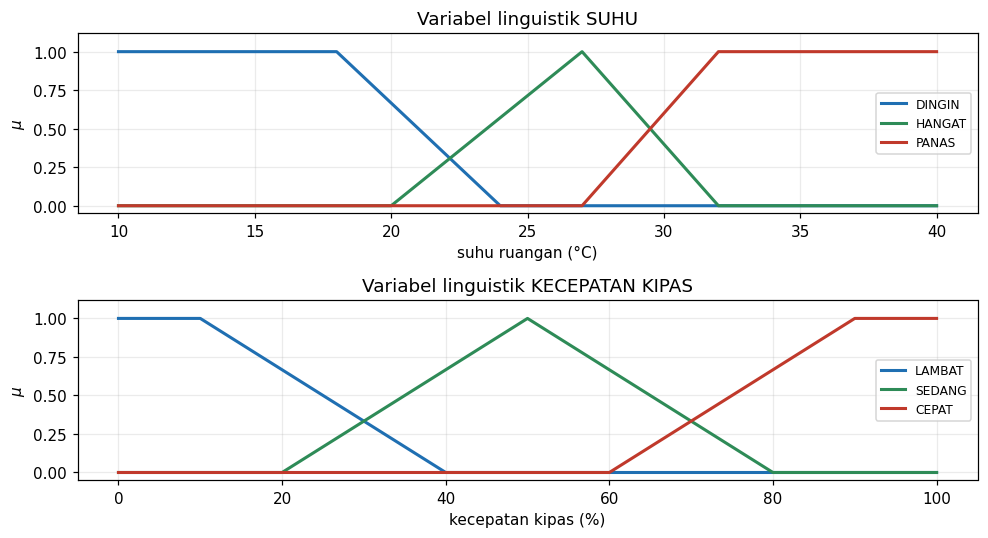

In [14]:
if GAMBAR:
    fig, axs = plt.subplots(2, 1, figsize=(9, 5), dpi=110)
    xs = [10 + 0.05 * i for i in range(601)]
    for nama, warna in (("DINGIN", "#1F6FB2"), ("HANGAT", "#2E8B57"), ("PANAS", "#C0392B")):
        axs[0].plot(xs, [SUHU[nama](v) for v in xs], color=warna, lw=2, label=nama)
    axs[0].set_xlabel("suhu ruangan (°C)"); axs[0].set_title("Variabel linguistik SUHU")
    ys = [0.2 * i for i in range(501)]
    for nama, warna in (("LAMBAT", "#1F6FB2"), ("SEDANG", "#2E8B57"), ("CEPAT", "#C0392B")):
        axs[1].plot(ys, [KIPAS[nama](v) for v in ys], color=warna, lw=2, label=nama)
    axs[1].set_xlabel("kecepatan kipas (%)"); axs[1].set_title("Variabel linguistik KECEPATAN KIPAS")
    for ax in axs:
        ax.set_ylabel(r"$\mu$"); ax.set_ylim(-0.05, 1.12); ax.grid(alpha=0.25); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

### Pertanyaan 4
Carilah suhu yang membuat DINGIN dan HANGAT bernilai **sama besar**, lalu bandingkan hasilnya dengan
tetapan `BATAS_DINGIN_HANGAT` pada Langkah 8. Mengapa titik itu penting?

In [15]:
# DINGIN menurun pada 18..24: (24-x)/6; HANGAT menaik pada 20..27: (x-20)/7.
suhu_sama = 288 / 13
batas_dingin_hangat = 22.15
mu_dingin_sama = SUHU["DINGIN"](suhu_sama)
mu_hangat_sama = SUHU["HANGAT"](suhu_sama)
print(f"Suhu potong = {suhu_sama:.4f} C")
print(f"mu_DINGIN = {mu_dingin_sama:.4f}; mu_HANGAT = {mu_hangat_sama:.4f}")
print(f"BATAS_DINGIN_HANGAT = {batas_dingin_hangat:.2f} C; selisih = {abs(suhu_sama - batas_dingin_hangat):.4f} C")
print("Titik potong memberi batas keputusan tegas yang seimbang: kedua aturan bertetangga sama kuat di sana.")

Suhu potong = 22.1538 C
mu_DINGIN = 0.3077; mu_HANGAT = 0.3077
BATAS_DINGIN_HANGAT = 22.15 C; selisih = 0.0038 C
Titik potong memberi batas keputusan tegas yang seimbang: kedua aturan bertetangga sama kuat di sana.


## G. Langkah 5 — Fuzzifikasi

Fuzzifikasi mengubah satu bilangan menjadi derajat keanggotaan pada setiap himpunan fuzzy.

In [16]:
# ---- Langkah 5: fuzzifikasi ---------------------------------------------
def fuzzifikasi(suhu):
    """Mengubah satu nilai numerik menjadi derajat keanggotaan tiap himpunan."""
    return {nama: fungsi(suhu) for nama, fungsi in SUHU.items()}

In [17]:
for suhu in (18.0, 22.0, 26.0, 30.0, 35.0):
    d = fuzzifikasi(suhu)
    print(f"suhu {suhu:>5.1f} C  ->  " +
          "   ".join(f"{k} {v:.2f}" for k, v in d.items()))

suhu  18.0 C  ->  DINGIN 1.00   HANGAT 0.00   PANAS 0.00
suhu  22.0 C  ->  DINGIN 0.33   HANGAT 0.29   PANAS 0.00
suhu  26.0 C  ->  DINGIN 0.00   HANGAT 0.86   PANAS 0.00
suhu  30.0 C  ->  DINGIN 0.00   HANGAT 0.40   PANAS 0.60
suhu  35.0 C  ->  DINGIN 0.00   HANGAT 0.00   PANAS 1.00


## H. Langkah 6 — Inferensi Mamdani

Dua pekerjaan pada tahap ini:

1. **Firing strength** ($\alpha$) — seberapa kuat setiap aturan menyala. Karena setiap aturan pada kasus
   ini hanya memiliki satu anteseden, $\alpha$ sama dengan derajat keanggotaan antesedennya.
2. **Agregasi** — setiap himpunan keluaran dipotong setinggi $\alpha$-nya (operator `min`), lalu seluruh
   hasil pemotongan digabungkan (operator `max`).

In [18]:
# ---- Langkah 6: inferensi Mamdani ---------------------------------------
def kuat_penyalaan(derajat):
    """Firing strength tiap aturan. Satu anteseden: langsung derajatnya."""
    return [(nama, anteseden, konsekuen, derajat[anteseden])
            for nama, anteseden, konsekuen in ATURAN]


def agregasi(penyalaan):
    """Memotong tiap himpunan keluaran pada firing strength, lalu digabung.

    Pemotongan memakai min (clipping), penggabungan memakai max — inilah
    metode 'clipped centre of gravity' pada Engelbrecht (2007), Subbab 21.2.3.
    """
    hasil = []
    for y in DOMAIN_KIPAS:
        nilai = 0.0
        for _, _, konsekuen, alfa in penyalaan:
            if alfa > 0.0:
                nilai = max(nilai, min(alfa, KIPAS[konsekuen](y)))
        hasil.append(nilai)
    return hasil

In [19]:
derajat = fuzzifikasi(30.0)
penyalaan = kuat_penyalaan(derajat)

for nama, ant, kon, alfa in penyalaan:
    keadaan = "aktif" if alfa > 0 else "padam"
    print(f"{nama}: JIKA suhu {ant:<6} MAKA kipas {kon:<6} -> alfa = {alfa:.2f}  ({keadaan})")

mu = agregasi(penyalaan)
print()
baris("Kecepatan", "mu gabungan", lebar=16)
print("-" * 30)
for y in range(0, 101, 10):
    baris(y, f"{mu[y]:.2f}", lebar=16)

R1: JIKA suhu DINGIN MAKA kipas LAMBAT -> alfa = 0.00  (padam)
R2: JIKA suhu HANGAT MAKA kipas SEDANG -> alfa = 0.40  (aktif)
R3: JIKA suhu PANAS  MAKA kipas CEPAT  -> alfa = 0.60  (aktif)

Kecepatan       mu gabungan
------------------------------
0               0.00
10              0.00
20              0.00
30              0.33
40              0.40
50              0.40
60              0.40
70              0.33
80              0.60
90              0.60
100             0.60


## I. Langkah 7 — Defuzzifikasi dengan Titik Berat

Pada domain diskret (Engelbrecht, 2007, Persamaan 21.11):

$$\text{keluaran} = \frac{\sum_i y_i \, \mu_C(y_i)}{\sum_i \mu_C(y_i)}$$

Bayangkan daerah keluaran sebagai sebuah lempengan: keluarannya adalah titik tempat lempengan itu
seimbang bila ditumpu.

In [20]:
# ---- Langkah 7: defuzzifikasi -------------------------------------------
def centroid(mu):
    """Titik berat pada domain diskret (Engelbrecht, 2007, Persamaan 21.11).

        keluaran = sum(y_i mu(y_i)) / sum(mu(y_i))
    """
    atas = sum(y * m for y, m in zip(DOMAIN_KIPAS, mu))
    bawah = sum(mu)
    return atas / bawah if bawah > 0 else 0.0


def rerata_maksimum(mu):
    """Pembanding sederhana: rata-rata titik yang keanggotaannya tertinggi."""
    puncak = max(mu)
    if puncak == 0.0:
        return 0.0
    titik = [y for y, m in zip(DOMAIN_KIPAS, mu) if m == puncak]
    return sum(titik) / len(titik)


def max_min(penyalaan):
    """Metode max-min: hanya aturan terkuat yang dipakai (Subbab 21.2.3)."""
    aktif = [p for p in penyalaan if p[3] > 0.0]
    if not aktif:
        return 0.0
    terkuat = max(aktif, key=lambda p: p[3])
    mu = [min(terkuat[3], KIPAS[terkuat[2]](y)) for y in DOMAIN_KIPAS]
    return centroid(mu)


def kendali_fuzzy(suhu):
    """Seluruh rangkaian: fuzzifikasi → inferensi → defuzzifikasi."""
    derajat = fuzzifikasi(suhu)
    penyalaan = kuat_penyalaan(derajat)
    mu = agregasi(penyalaan)
    return centroid(mu), derajat, penyalaan, mu


# Titik potong antara himpunan suhu yang bertetangga — di sanalah dua
# himpunan memiliki derajat keanggotaan yang sama besar.
BATAS_DINGIN_HANGAT = 22.15
BATAS_HANGAT_PANAS = 29.5


def pusat_himpunan(nama):
    """Titik berat sebuah himpunan keluaran, dipakai sebagai aksi tegas."""
    mu = [KIPAS[nama](y) for y in DOMAIN_KIPAS]
    return centroid(mu)


def kendali_tegas(suhu):
    """Pembanding: tiga aksi yang sama, tetapi dipilih dengan batas kaku.

    Aksinya diambil dari titik berat ketiga himpunan keluaran, sedangkan
    batasnya diletakkan pada titik potong himpunan suhu. Dengan begitu
    perbedaan yang terlihat benar-benar berasal dari ketegasan batas,
    bukan dari pilihan angka yang berbeda.
    """
    if suhu > BATAS_HANGAT_PANAS:
        return pusat_himpunan('CEPAT')
    if suhu > BATAS_DINGIN_HANGAT:
        return pusat_himpunan('SEDANG')
    return pusat_himpunan('LAMBAT')

In [21]:
atas = sum(y * m for y, m in zip(DOMAIN_KIPAS, mu))
bawah = sum(mu)
print(f"sum(y mu(y)) = {atas:.2f}")
print(f"sum(mu(y))   = {bawah:.2f}")
print(f"centroid     = {atas:.2f} / {bawah:.2f} = {centroid(mu):.2f}")
print()
print(f"Kecepatan kipas untuk suhu 30 C = {centroid(mu):.1f} persen")

sum(y mu(y)) = 2320.37
sum(mu(y))   = 34.77
centroid     = 2320.37 / 34.77 = 66.74

Kecepatan kipas untuk suhu 30 C = 66.7 persen


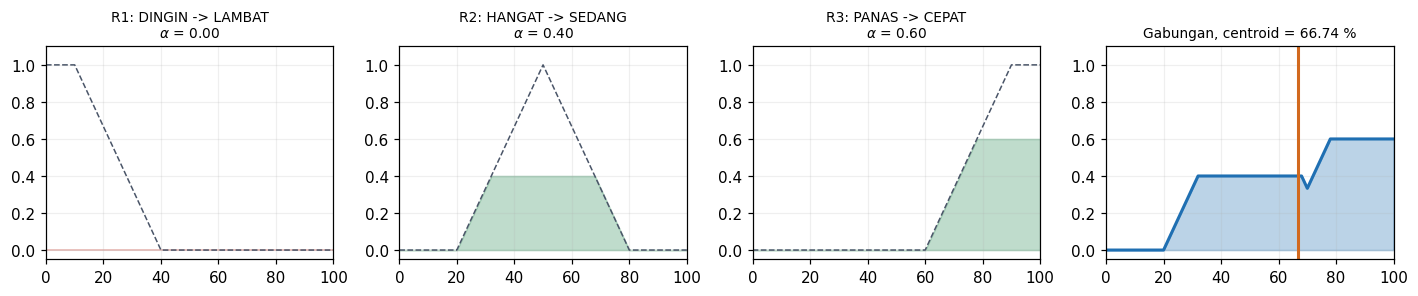

In [22]:
if GAMBAR:
    fig, axs = plt.subplots(1, 4, figsize=(13, 2.8), dpi=110)
    ys = [0.2 * i for i in range(501)]
    for k, (nama, ant, kon, alfa) in enumerate(penyalaan):
        dasar = [KIPAS[kon](v) for v in ys]
        potong = [min(alfa, d) for d in dasar]
        axs[k].plot(ys, dasar, color="#4A5568", lw=1, ls="--")
        axs[k].fill_between(ys, potong, color="#2E8B57" if alfa > 0 else "#C0392B", alpha=0.3)
        axs[k].set_title(f"{nama}: {ant} -> {kon}\n" + r"$\alpha$ = " + f"{alfa:.2f}", fontsize=9)
    halus = []
    for v in ys:
        nilai = 0.0
        for _, _, kon, alfa in penyalaan:
            if alfa > 0:
                nilai = max(nilai, min(alfa, KIPAS[kon](v)))
        halus.append(nilai)
    axs[3].fill_between(ys, halus, color="#1F6FB2", alpha=0.3)
    axs[3].plot(ys, halus, color="#1F6FB2", lw=2)
    axs[3].axvline(centroid(mu), color="#D2691E", lw=2)
    axs[3].set_title(f"Gabungan, centroid = {centroid(mu):.2f} %", fontsize=9)
    for ax in axs:
        ax.set_ylim(-0.05, 1.1); ax.set_xlim(0, 100); ax.grid(alpha=0.2)
    plt.tight_layout(); plt.show()

### Pertanyaan 5
Hitung ulang centroid untuk kasus yang sama, tetapi hanya memakai titik $y = 0, 10, 20, \dots, 100$
(langkah 10, bukan 1). Bandingkan dengan hasil program. Mengapa keduanya sedikit berbeda, dan ke arah
mana kesalahannya?

In [23]:
q5_derajat = fuzzifikasi(30.0)
q5_penyalaan = kuat_penyalaan(q5_derajat)
q5_mu = agregasi(q5_penyalaan)
y_kasar = [float(y) for y in range(0, 101, 10)]
mu_kasar = [max((min(alfa, KIPAS[kon](y)) for _, _, kon, alfa in q5_penyalaan), default=0.0) for y in y_kasar]
centroid_kasar = sum(y * m for y, m in zip(y_kasar, mu_kasar)) / sum(mu_kasar)
centroid_halus = centroid(q5_mu)
print(f"Centroid langkah 1  = {centroid_halus:.4f} persen")
print(f"Centroid langkah 10 = {centroid_kasar:.4f} persen")
print(f"Selisih (kasar - halus) = {centroid_kasar - centroid_halus:+.4f} persen")
arah = "lebih tinggi" if centroid_kasar > centroid_halus else "lebih rendah" if centroid_kasar < centroid_halus else "sama"
print(f"Sampel yang lebih jarang memberi pendekatan {arah}; titik-titik di antara sampel tidak ikut dihitung, sehingga galatnya bergantung pada bentuk kurva.")

Centroid langkah 1  = 66.7411 persen
Centroid langkah 10 = 69.6364 persen
Selisih (kasar - halus) = +2.8952 persen
Sampel yang lebih jarang memberi pendekatan lebih tinggi; titik-titik di antara sampel tidak ikut dihitung, sehingga galatnya bergantung pada bentuk kurva.


## J. Langkah 8 — Kurva Kendali: Fuzzy Dibandingkan Aturan Tegas

Agar perbandingannya adil, aturan tegas pembanding memakai **tindakan yang sama persis** dengan sistem
fuzzy — yaitu titik berat ketiga himpunan keluaran — dan batasnya diletakkan tepat pada titik potong
himpunan suhu yang bertetangga.

In [24]:
def kendali_fuzzy(suhu):
    """Seluruh rangkaian: fuzzifikasi → inferensi → defuzzifikasi."""
    derajat = fuzzifikasi(suhu)
    penyalaan = kuat_penyalaan(derajat)
    mu = agregasi(penyalaan)
    return centroid(mu), derajat, penyalaan, mu


# Titik potong antara himpunan suhu yang bertetangga — di sanalah dua
# himpunan memiliki derajat keanggotaan yang sama besar.
BATAS_DINGIN_HANGAT = 22.15
BATAS_HANGAT_PANAS = 29.5


def pusat_himpunan(nama):
    """Titik berat sebuah himpunan keluaran, dipakai sebagai aksi tegas."""
    mu = [KIPAS[nama](y) for y in DOMAIN_KIPAS]
    return centroid(mu)


def kendali_tegas(suhu):
    """Pembanding: tiga aksi yang sama, tetapi dipilih dengan batas kaku.

    Aksinya diambil dari titik berat ketiga himpunan keluaran, sedangkan
    batasnya diletakkan pada titik potong himpunan suhu. Dengan begitu
    perbedaan yang terlihat benar-benar berasal dari ketegasan batas,
    bukan dari pilihan angka yang berbeda.
    """
    if suhu > BATAS_HANGAT_PANAS:
        return pusat_himpunan('CEPAT')
    if suhu > BATAS_DINGIN_HANGAT:
        return pusat_himpunan('SEDANG')
    return pusat_himpunan('LAMBAT')

In [25]:
print("Tindakan pembanding (titik berat himpunan keluaran):")
for nama in ("LAMBAT", "SEDANG", "CEPAT"):
    print(f"   {nama:<7} -> {pusat_himpunan(nama):.2f} persen")
print(f"Batas: {BATAS_DINGIN_HANGAT} C dan {BATAS_HANGAT_PANAS} C")
print()

baris("Suhu", "Fuzzy (%)", "Tegas (%)", "Selisih", lebar=13)
print("-" * 52)
for x in range(18, 37):
    f = kendali_fuzzy(float(x))[0]
    t = kendali_tegas(float(x))
    baris(x, f"{f:.1f}", f"{t:.1f}", f"{f - t:+.1f}", lebar=13)

Tindakan pembanding (titik berat himpunan keluaran):
   LAMBAT  -> 13.72 persen
   SEDANG  -> 50.00 persen
   CEPAT   -> 86.28 persen
Batas: 22.15 C dan 29.5 C

Suhu         Fuzzy (%)    Tegas (%)    Selisih
----------------------------------------------------
18           13.7         13.7         +0.0
19           14.4         13.7         +0.7
20           15.3         13.7         +1.6
21           27.0         13.7         +13.3
22           36.2         13.7         +22.5
23           43.8         50.0         -6.2
24           50.0         50.0         +0.0
25           50.0         50.0         -0.0
26           50.0         50.0         +0.0
27           50.0         50.0         +0.0
28           55.4         50.0         +5.4
29           60.9         50.0         +10.9
30           66.7         86.3         -19.5
31           74.4         86.3         -11.9
32           86.3         86.3         +0.0
33           86.3         86.3         +0.0
34           86.3         86.3

In [26]:
print("Di sekitar batas 29,5 C:")
for x in (29.3, 29.4, 29.5, 29.6, 29.7):
    print(f"   suhu {x:.1f}  ->  fuzzy {kendali_fuzzy(x)[0]:6.2f} persen"
          f"   tegas {kendali_tegas(x):6.2f} persen")

lompat_tegas = kendali_tegas(29.6) - kendali_tegas(29.4)
lompat_fuzzy = kendali_fuzzy(29.6)[0] - kendali_fuzzy(29.4)[0]
print()
print(f"Perubahan suhu 0,2 C mengubah keluaran:")
print(f"   aturan tegas : {lompat_tegas:.1f} persen")
print(f"   fuzzy        : {lompat_fuzzy:.2f} persen")

Di sekitar batas 29,5 C:
   suhu 29.3  ->  fuzzy  62.60 persen   tegas  50.00 persen
   suhu 29.4  ->  fuzzy  63.16 persen   tegas  50.00 persen
   suhu 29.5  ->  fuzzy  63.73 persen   tegas  50.00 persen
   suhu 29.6  ->  fuzzy  64.31 persen   tegas  86.28 persen
   suhu 29.7  ->  fuzzy  64.90 persen   tegas  86.28 persen

Perubahan suhu 0,2 C mengubah keluaran:
   aturan tegas : 36.3 persen
   fuzzy        : 1.15 persen


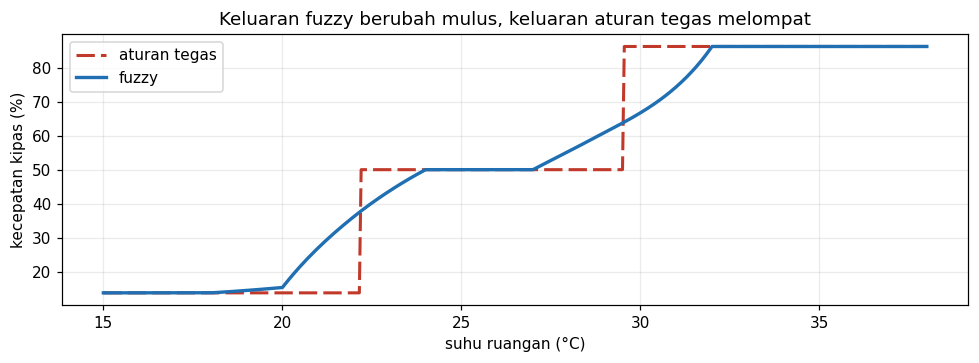

In [27]:
if GAMBAR:
    xs = [15 + 0.05 * i for i in range(461)]
    plt.figure(figsize=(9, 3.4), dpi=110)
    plt.plot(xs, [kendali_tegas(v) for v in xs], color="#C0392B", lw=2,
             ls=(0, (6, 2)), label="aturan tegas")
    plt.plot(xs, [kendali_fuzzy(v)[0] for v in xs], color="#1F6FB2", lw=2.2, label="fuzzy")
    plt.xlabel("suhu ruangan (°C)"); plt.ylabel("kecepatan kipas (%)")
    plt.title("Keluaran fuzzy berubah mulus, keluaran aturan tegas melompat")
    plt.grid(alpha=0.25); plt.legend(); plt.tight_layout(); plt.show()

### Pertanyaan 6
Pada rentang 24 °C sampai 27 °C keluaran fuzzy **tetap 50,0%** meskipun suhunya berubah. Jelaskan
penyebabnya, lalu usulkan satu perubahan rancangan yang dapat mengatasinya.

In [28]:
for suhu_uji in (24.0, 25.0, 26.0, 27.0):
    d = fuzzifikasi(suhu_uji)
    alfa = kuat_penyalaan(d)
    aktif = [(nama, round(a, 3)) for nama, _, _, a in alfa if a > 0]
    print(f"{suhu_uji:.0f} C: aturan aktif = {aktif}; keluaran = {kendali_fuzzy(suhu_uji)[0]:.2f}%")
print("Pada 24-27 C hanya aturan HANGAT -> SEDANG yang aktif: DINGIN sudah nol dan PANAS belum aktif.")
print("Himpunan SEDANG simetris terhadap 50%; mengubah tinggi clipping-nya tidak mengubah centroid, sehingga keluaran tetap 50%.")
print("Perbaikan: lebarkan DINGIN hingga bertumpang-tindih dengan HANGAT, lalu evaluasi ulang aturan yang sama.")

def kendali_fuzzy_dingin_diperlebar(suhu):
    derajat_lokal = {"DINGIN": trapesium(suhu, 10.0, 10.0, 20.0, 27.0),
                     "HANGAT": SUHU["HANGAT"](suhu), "PANAS": SUHU["PANAS"](suhu)}
    penyalaan_lokal = kuat_penyalaan(derajat_lokal)
    return centroid(agregasi(penyalaan_lokal))

print("Contoh setelah DINGIN diperlebar:")
for suhu_uji in (24.0, 25.0, 26.0, 27.0):
    print(f"{suhu_uji:.0f} C -> {kendali_fuzzy_dingin_diperlebar(suhu_uji):.2f}%")

24 C: aturan aktif = [('R2', 0.571)]; keluaran = 50.00%
25 C: aturan aktif = [('R2', 0.714)]; keluaran = 50.00%
26 C: aturan aktif = [('R2', 0.857)]; keluaran = 50.00%
27 C: aturan aktif = [('R2', 1.0)]; keluaran = 50.00%
Pada 24-27 C hanya aturan HANGAT -> SEDANG yang aktif: DINGIN sudah nol dan PANAS belum aktif.
Himpunan SEDANG simetris terhadap 50%; mengubah tinggi clipping-nya tidak mengubah centroid, sehingga keluaran tetap 50%.
Perbaikan: lebarkan DINGIN hingga bertumpang-tindih dengan HANGAT, lalu evaluasi ulang aturan yang sama.
Contoh setelah DINGIN diperlebar:
24 C -> 38.28%
25 C -> 42.23%
26 C -> 46.12%
27 C -> 50.00%


## K. Langkah 9 — Tiga Cara Defuzzifikasi

Metode yang berbeda menghasilkan angka yang berbeda untuk kasus yang sama.

In [29]:
def rerata_maksimum(mu):
    """Pembanding sederhana: rata-rata titik yang keanggotaannya tertinggi."""
    puncak = max(mu)
    if puncak == 0.0:
        return 0.0
    titik = [y for y, m in zip(DOMAIN_KIPAS, mu) if m == puncak]
    return sum(titik) / len(titik)


def max_min(penyalaan):
    """Metode max-min: hanya aturan terkuat yang dipakai (Subbab 21.2.3)."""
    aktif = [p for p in penyalaan if p[3] > 0.0]
    if not aktif:
        return 0.0
    terkuat = max(aktif, key=lambda p: p[3])
    mu = [min(terkuat[3], KIPAS[terkuat[2]](y)) for y in DOMAIN_KIPAS]
    return centroid(mu)

In [30]:
baris("Metode", "Keluaran (%)", lebar=30)
print("-" * 44)
baris("Centroid terpotong", f"{centroid(mu):.2f}", lebar=30)
baris("Max-min", f"{max_min(penyalaan):.2f}", lebar=30)
baris("Rata-rata titik puncak", f"{rerata_maksimum(mu):.2f}", lebar=30)

Metode                        Keluaran (%)
--------------------------------------------
Centroid terpotong            66.74
Max-min                       84.32
Rata-rata titik puncak        89.00


### Pertanyaan 7
Mengapa metode max-min menghasilkan angka yang jauh lebih besar daripada centroid terpotong pada kasus
suhu 30 °C? Keterangan apa yang **hilang** ketika max-min dipakai?

In [31]:
q7_derajat = fuzzifikasi(30.0)
q7_penyalaan = kuat_penyalaan(q7_derajat)
q7_mu = agregasi(q7_penyalaan)
print(f"Centroid terpotong = {centroid(q7_mu):.2f}%")
print(f"Max-min            = {max_min(q7_penyalaan):.2f}%")
print("Max-min memilih hanya satu aturan terkuat (pada 30 C: PANAS -> CEPAT) dan membuang kontribusi aturan HANGAT -> SEDANG yang masih aktif.")
print("Akibatnya, bentuk/luas kontribusi aturan lain dan kompromi gabungan antar-konsekuen tidak lagi tercermin pada keluaran.")

Centroid terpotong = 66.74%
Max-min            = 84.32%
Max-min memilih hanya satu aturan terkuat (pada 30 C: PANAS -> CEPAT) dan membuang kontribusi aturan HANGAT -> SEDANG yang masih aktif.
Akibatnya, bentuk/luas kontribusi aturan lain dan kompromi gabungan antar-konsekuen tidak lagi tercermin pada keluaran.


## L. Tugas Mandiri

Kerjakan seluruh tugas berikut pada sel yang tersedia. Sertakan keluaran program sebagai bukti, bukan
hanya uraian.

### Tugas 1 — Menambah masukan kedua
Perluas sistem sehingga memiliki **dua masukan**, yaitu suhu dan kelembapan, dengan aturan berbentuk
`JIKA suhu ... DAN kelembapan ... MAKA kipas ...`. Pakai operator `min` untuk menghitung firing strength.
Sajikan hasilnya sebagai tabel keluaran untuk sembilan pasangan nilai, dan telusuri satu kasus secara
lengkap.

In [32]:
# Himpunan kelembapan (%): tiga istilah linguistik pada domain 0..100.
KELEMBAPAN = {
    "KERING": lambda h: trapesium(h, 0.0, 0.0, 30.0, 50.0),
    "NORMAL": lambda h: segitiga(h, 30.0, 55.0, 80.0),
    "LEMBAP": lambda h: trapesium(h, 60.0, 80.0, 100.0, 100.0),
}

# Baris = suhu; kolom = kelembapan. Konsekuen ditentukan secara monoton.
ATURAN_DUA_INPUT = [
    ("DINGIN", "KERING", "LAMBAT"), ("DINGIN", "NORMAL", "LAMBAT"), ("DINGIN", "LEMBAP", "SEDANG"),
    ("HANGAT", "KERING", "LAMBAT"), ("HANGAT", "NORMAL", "SEDANG"), ("HANGAT", "LEMBAP", "CEPAT"),
    ("PANAS", "KERING", "SEDANG"), ("PANAS", "NORMAL", "CEPAT"), ("PANAS", "LEMBAP", "CEPAT"),
]

def sistem_dua_masukan(suhu, kelembapan, operator_dan=min):
    """Inferensi Mamdani dua masukan; operator_dan menghitung firing strength."""
    derajat_suhu = fuzzifikasi(suhu)
    derajat_lembap = {nama: fungsi(kelembapan) for nama, fungsi in KELEMBAPAN.items()}
    penyalaan_dua = [(nama_s, nama_h, konsekuen,
                      operator_dan(derajat_suhu[nama_s], derajat_lembap[nama_h]))
                     for nama_s, nama_h, konsekuen in ATURAN_DUA_INPUT]
    hasil_agregasi = [max((min(alfa, KIPAS[konsekuen](y)) for _, _, konsekuen, alfa in penyalaan_dua), default=0.0)
                      for y in DOMAIN_KIPAS]
    return centroid(hasil_agregasi), derajat_suhu, derajat_lembap, penyalaan_dua, hasil_agregasi

print("Keluaran untuk sembilan pasangan suhu dan kelembapan:")
baris("Suhu (C)", "Kelembapan (%)", "Kipas (%)", lebar=18)
print("-" * 54)
for suhu_uji in (18.0, 27.0, 35.0):
    for lembap_uji in (20.0, 55.0, 90.0):
        keluaran, _, _, _, _ = sistem_dua_masukan(suhu_uji, lembap_uji)
        baris(f"{suhu_uji:.0f}", f"{lembap_uji:.0f}", f"{keluaran:.2f}", lebar=18)

suhu_telusur, lembap_telusur = 30.0, 70.0
keluaran, derajat_suhu, derajat_lembap, aktifasi, _ = sistem_dua_masukan(suhu_telusur, lembap_telusur)
print(f"\nPenelusuran lengkap: suhu={suhu_telusur:.0f} C, kelembapan={lembap_telusur:.0f}%")
print("Derajat suhu:", {k: round(v, 3) for k, v in derajat_suhu.items()})
print("Derajat kelembapan:", {k: round(v, 3) for k, v in derajat_lembap.items()})
for nama_s, nama_h, konsekuen, alfa in aktifasi:
    if alfa > 0:
        print(f"JIKA {nama_s} DAN {nama_h} MAKA {konsekuen}: min({derajat_suhu[nama_s]:.3f}, {derajat_lembap[nama_h]:.3f}) = {alfa:.3f}")
print(f"Agregasi min-potong/max-gabung pada domain kipas 0..100 menghasilkan centroid {keluaran:.2f}%.")

Keluaran untuk sembilan pasangan suhu dan kelembapan:
Suhu (C)          Kelembapan (%)    Kipas (%)
------------------------------------------------------
18                20                13.72
18                55                13.72
18                90                50.00
27                20                13.72
27                55                50.00
27                90                86.28
35                20                50.00
35                55                86.28
35                90                86.28

Penelusuran lengkap: suhu=30 C, kelembapan=70%
Derajat suhu: {'DINGIN': 0.0, 'HANGAT': 0.4, 'PANAS': 0.6}
Derajat kelembapan: {'KERING': 0.0, 'NORMAL': 0.4, 'LEMBAP': 0.5}
JIKA HANGAT DAN NORMAL MAKA SEDANG: min(0.400, 0.400) = 0.400
JIKA HANGAT DAN LEMBAP MAKA CEPAT: min(0.400, 0.500) = 0.400
JIKA PANAS DAN NORMAL MAKA CEPAT: min(0.600, 0.400) = 0.400
JIKA PANAS DAN LEMBAP MAKA CEPAT: min(0.600, 0.500) = 0.500
Agregasi min-potong/max-gabung pada domain kipas 0.

### Tugas 2 — Membandingkan t-norm
Ubah operator DAN dari `min` menjadi hasil kali pada sistem dua masukan di atas, lalu bandingkan
keluarannya pada lima pasangan nilai yang sama. Jelaskan arah perbedaannya **pada tingkat aturan** dan
**pada tingkat keluaran** — keduanya belum tentu searah.

In [33]:
pasangan_perbandingan = ((21.5, 35.0), (23.25, 75.0), (25.0, 45.0), (30.0, 70.0), (35.0, 90.0))
baris("Suhu", "Kelembapan", "Min (%)", "Produk (%)", "Produk - min", lebar=16)
print("-" * 80)
selisih_t_norm = []
for suhu_uji, lembap_uji in pasangan_perbandingan:
    out_min, _, _, _, _ = sistem_dua_masukan(suhu_uji, lembap_uji, min)
    out_produk, _, _, _, _ = sistem_dua_masukan(suhu_uji, lembap_uji, lambda a, b: a * b)
    selisih = out_produk - out_min
    selisih_t_norm.append((selisih, suhu_uji, lembap_uji))
    baris(f"{suhu_uji:.2f}", f"{lembap_uji:.0f}", f"{out_min:.2f}", f"{out_produk:.2f}", f"{selisih:+.2f}", lebar=16)
beda_terbesar = max(selisih_t_norm)
beda_terkecil = min(selisih_t_norm)
print(f"\nPada tingkat aturan, a*b <= min(a,b), sehingga setiap firing strength produk tidak lebih besar.")
print(f"Pada tingkat keluaran, centroid dapat bergeser ke salah satu arah karena proporsi relatif aturan berubah.")
print(f"Untuk sampel ini, selisih terbesar: {beda_terbesar[0]:+.2f}% pada ({beda_terbesar[1]:.2f} C, {beda_terbesar[2]:.0f}%).")
print(f"Selisih terkecil: {beda_terkecil[0]:+.2f}% pada ({beda_terkecil[1]:.2f} C, {beda_terkecil[2]:.0f}%).")
print("Contoh ini menunjukkan keluaran produk bisa lebih tinggi maupun lebih rendah: centroid bergantung pada bobot relatif konsekuen setelah agregasi, bukan hanya pada kecilnya tiap alpha.")

Suhu            Kelembapan      Min (%)         Produk (%)      Produk - min
--------------------------------------------------------------------------------
21.50           35              31.25           23.05           -8.20
23.25           75              63.48           71.07           +7.59
25.00           45              42.57           43.39           +0.81
30.00           70              65.13           67.53           +2.40
35.00           90              86.28           86.28           +0.00

Pada tingkat aturan, a*b <= min(a,b), sehingga setiap firing strength produk tidak lebih besar.
Pada tingkat keluaran, centroid dapat bergeser ke salah satu arah karena proporsi relatif aturan berubah.
Untuk sampel ini, selisih terbesar: +7.59% pada (23.25 C, 75%).
Selisih terkecil: -8.20% pada (21.50 C, 35%).
Contoh ini menunjukkan keluaran produk bisa lebih tinggi maupun lebih rendah: centroid bergantung pada bobot relatif konsekuen setelah agregasi, bukan hanya pada kecilnya tiap alp

### Tugas 3 — Menerapkan hedge
Tambahkan himpunan SANGAT PANAS yang dibangun dari himpunan PANAS dengan hedge pemusatan, lalu buat satu
aturan yang memakainya. Periksa apakah kurva kendali menjadi lebih curam pada suhu tinggi. Bila ternyata
tidak berubah, cari tahu sebabnya sebelum mengubah rancangan.

Perbandingan aturan PANAS biasa dengan aturan SANGAT PANAS (PANAS^2):
Suhu (C)            Biasa (%)           Sangat panas (%)
------------------------------------------------------------
28                  55.43               51.14
30                  66.74               62.21
32                  86.28               86.28
34                  86.28               86.28
36                  86.28               86.28
38                  86.28               86.28
40                  86.28               86.28
Perubahan keluaran satu derajat terbesar pada 27..40 C: biasa 11.89; sangat panas 13.70 poin persentase.


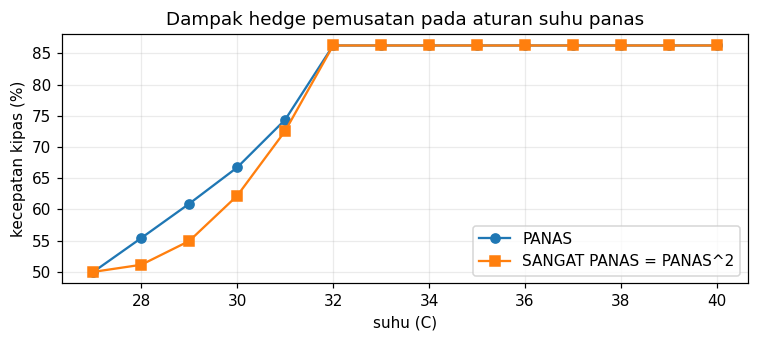

Di sekitar transisi terpanas, maksimum perubahan satu derajat naik dari 11.89 menjadi 13.70 poin, jadi kurva varian lebih curam di bagian itu.
Setelah PANAS mencapai 1 (mulai 32 C), PANAS^2 juga tetap 1; firing strength dan keluaran CEPAT sama-sama jenuh, sehingga kedua kurva kembali berimpit.


In [34]:
def kendali_super_panas(suhu):
    """Varian yang mengganti aturan PANAS dengan anteseden PANAS^2."""
    derajat_lokal = fuzzifikasi(suhu)
    derajat_lokal["SANGAT_PANAS"] = sangat(SUHU["PANAS"](suhu))
    penyalaan_lokal = [(nama, "SANGAT_PANAS" if anteseden == "PANAS" else anteseden, konsekuen,
                        derajat_lokal["SANGAT_PANAS"] if anteseden == "PANAS" else derajat_lokal[anteseden])
                       for nama, anteseden, konsekuen in ATURAN]
    mu_lokal = [max((min(alfa, KIPAS[konsekuen](y)) for _, _, konsekuen, alfa in penyalaan_lokal), default=0.0)
                for y in DOMAIN_KIPAS]
    return centroid(mu_lokal)

print("Perbandingan aturan PANAS biasa dengan aturan SANGAT PANAS (PANAS^2):")
baris("Suhu (C)", "Biasa (%)", "Sangat panas (%)", lebar=20)
print("-" * 60)
for suhu_uji in (28, 30, 32, 34, 36, 38, 40):
    baris(suhu_uji, f"{kendali_fuzzy(suhu_uji)[0]:.2f}", f"{kendali_super_panas(suhu_uji):.2f}", lebar=20)
xs_panas = list(range(27, 41))
biasa = [kendali_fuzzy(float(x))[0] for x in xs_panas]
super_panas = [kendali_super_panas(float(x)) for x in xs_panas]
laju_biasa = max(abs(b - a) for a, b in zip(biasa, biasa[1:]))
laju_super = max(abs(b - a) for a, b in zip(super_panas, super_panas[1:]))
print(f"Perubahan keluaran satu derajat terbesar pada 27..40 C: biasa {laju_biasa:.2f}; sangat panas {laju_super:.2f} poin persentase.")
if GAMBAR:
    plt.figure(figsize=(7, 3.2), dpi=110)
    plt.plot(xs_panas, biasa, marker="o", label="PANAS")
    plt.plot(xs_panas, super_panas, marker="s", label="SANGAT PANAS = PANAS^2")
    plt.xlabel("suhu (C)"); plt.ylabel("kecepatan kipas (%)")
    plt.title("Dampak hedge pemusatan pada aturan suhu panas")
    plt.grid(alpha=0.25); plt.legend(); plt.tight_layout(); plt.show()
print(f"Di sekitar transisi terpanas, maksimum perubahan satu derajat naik dari {laju_biasa:.2f} menjadi {laju_super:.2f} poin, jadi kurva varian lebih curam di bagian itu.")
print("Setelah PANAS mencapai 1 (mulai 32 C), PANAS^2 juga tetap 1; firing strength dan keluaran CEPAT sama-sama jenuh, sehingga kedua kurva kembali berimpit.")

### Tugas 4 — Kasus baru
Rancang sendiri satu fuzzy system sederhana untuk persoalan lain di lingkungan Anda — misalnya penentuan
lama lampu hijau berdasarkan panjang antrean kendaraan, atau penentuan kecerahan layar berdasarkan cahaya
sekitar. Gunakan **satu masukan, satu keluaran, dan tiga aturan**. Sertakan definisi himpunan fuzzy, basis
aturan, satu penelusuran lengkap, dan kurva kendalinya.

Himpunan masukan: ['PENDEK', 'SEDANG', 'PANJANG']
Himpunan keluaran (detik): ['SINGKAT', 'SEDANG', 'LAMA']
Basis aturan: [('PENDEK', 'SINGKAT'), ('SEDANG', 'SEDANG'), ('PANJANG', 'LAMA')]

Penelusuran pada antrean 65 kendaraan per 100:
Derajat keanggotaan: {'PENDEK': 0.0, 'SEDANG': 0.5, 'PANJANG': 0.167}
JIKA SEDANG MAKA SEDANG: alpha = 0.500
JIKA PANJANG MAKA LAMA: alpha = 0.167
Agregasi min-potong/max-gabung lalu centroid -> 65.67 detik.


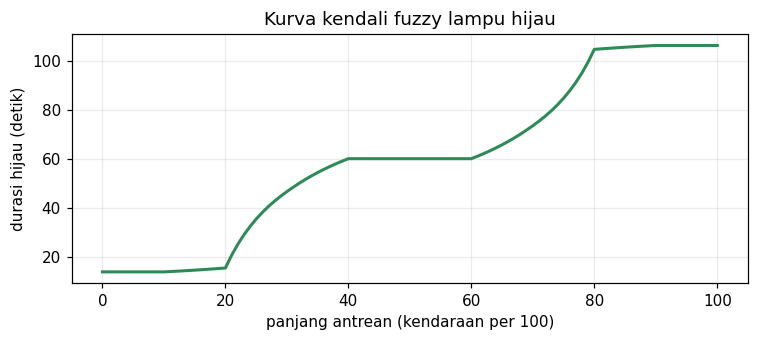

In [35]:
# Sistem baru: durasi lampu hijau berdasarkan panjang antrean (kendaraan per 100).
ANTREAN = {
    "PENDEK": lambda x: trapesium(x, 0.0, 0.0, 10.0, 40.0),
    "SEDANG": lambda x: segitiga(x, 20.0, 50.0, 80.0),
    "PANJANG": lambda x: trapesium(x, 60.0, 90.0, 100.0, 100.0),
}
DURASI = {
    "SINGKAT": lambda y: trapesium(y, 0.0, 0.0, 10.0, 40.0),
    "SEDANG": lambda y: segitiga(y, 20.0, 60.0, 100.0),
    "LAMA": lambda y: trapesium(y, 80.0, 110.0, 120.0, 120.0),
}
DOMAIN_DURASI = [float(y) for y in range(0, 121)]
ATURAN_LAMPU = [("PENDEK", "SINGKAT"), ("SEDANG", "SEDANG"), ("PANJANG", "LAMA")]

def kendali_lampu(panjang_antrean):
    derajat_antrean = {nama: fungsi(panjang_antrean) for nama, fungsi in ANTREAN.items()}
    penyalaan_lampu = [(anteseden, konsekuen, derajat_antrean[anteseden]) for anteseden, konsekuen in ATURAN_LAMPU]
    mu_durasi = [max((min(alfa, DURASI[konsekuen](y)) for _, konsekuen, alfa in penyalaan_lampu), default=0.0)
                 for y in DOMAIN_DURASI]
    atas = sum(y * m for y, m in zip(DOMAIN_DURASI, mu_durasi))
    bawah = sum(mu_durasi)
    return (atas / bawah if bawah else 0.0), derajat_antrean, penyalaan_lampu, mu_durasi

uji_antrean = 65.0
keluaran_lampu, derajat_antrean, penyalaan_lampu, mu_durasi = kendali_lampu(uji_antrean)
print("Himpunan masukan:", list(ANTREAN))
print("Himpunan keluaran (detik):", list(DURASI))
print("Basis aturan:", ATURAN_LAMPU)
print(f"\nPenelusuran pada antrean {uji_antrean:.0f} kendaraan per 100:")
print("Derajat keanggotaan:", {k: round(v, 3) for k, v in derajat_antrean.items()})
for anteseden, konsekuen, alfa in penyalaan_lampu:
    if alfa > 0:
        print(f"JIKA {anteseden} MAKA {konsekuen}: alpha = {alfa:.3f}")
print(f"Agregasi min-potong/max-gabung lalu centroid -> {keluaran_lampu:.2f} detik.")
if GAMBAR:
    xs_antrean = [float(x) for x in range(0, 101)]
    ys_lampu = [kendali_lampu(x)[0] for x in xs_antrean]
    plt.figure(figsize=(7, 3.2), dpi=110)
    plt.plot(xs_antrean, ys_lampu, color="#2E8B57", lw=2)
    plt.xlabel("panjang antrean (kendaraan per 100)"); plt.ylabel("durasi hijau (detik)")
    plt.title("Kurva kendali fuzzy lampu hijau")
    plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

### Tugas 5 — Analisis kemulusan
Untuk sistem rancangan Anda sendiri, hitunglah **perubahan keluaran terbesar** yang terjadi akibat
perubahan masukan sebesar satu satuan. Bandingkan dengan sistem beraturan tegas yang setara, lalu
simpulkan.

In [36]:
nilai_fuzzy_lampu = [kendali_lampu(float(x))[0] for x in range(0, 101)]
delta_fuzzy_lampu = [(abs(b - a), x, a, b) for x, (a, b) in enumerate(zip(nilai_fuzzy_lampu, nilai_fuzzy_lampu[1:]))]
maks_fuzzy = max(delta_fuzzy_lampu)

# Titik potong input PENDEK/SEDANG dan SEDANG/PANJANG berada di sekitar 30 dan 70.
def pusat_durasi(nama):
    bentuk = [DURASI[nama](y) for y in DOMAIN_DURASI]
    return sum(y * m for y, m in zip(DOMAIN_DURASI, bentuk)) / sum(bentuk)

def kendali_lampu_tegas(x):
    if x > 70:
        return pusat_durasi("LAMA")
    if x > 30:
        return pusat_durasi("SEDANG")
    return pusat_durasi("SINGKAT")

nilai_tegas_lampu = [kendali_lampu_tegas(float(x)) for x in range(0, 101)]
delta_tegas_lampu = [(abs(b - a), x, a, b) for x, (a, b) in enumerate(zip(nilai_tegas_lampu, nilai_tegas_lampu[1:]))]
maks_tegas = max(delta_tegas_lampu)
print(f"Fuzzy: perubahan maksimum per 1 unit antrean = {maks_fuzzy[0]:.3f} detik (antara {maks_fuzzy[1]} dan {maks_fuzzy[1] + 1}).")
print(f"Tegas: perubahan maksimum per 1 unit antrean = {maks_tegas[0]:.3f} detik (antara {maks_tegas[1]} dan {maks_tegas[1] + 1}).")
print(f"Keluaran tegas berpindah dari {maks_tegas[2]:.2f} ke {maks_tegas[3]:.2f} detik saat melewati batas, sedangkan keluaran fuzzy berubah bertahap.")
print("Kesimpulan: pada rancangan ini, tumpang-tindih fungsi keanggotaan membuat perubahan keluaran lokal jauh lebih kecil dan menghindari lonjakan pada batas aturan.")

Fuzzy: perubahan maksimum per 1 unit antrean = 5.152 detik (antara 79 dan 80).
Tegas: perubahan maksimum per 1 unit antrean = 46.281 detik (antara 30 dan 31).
Keluaran tegas berpindah dari 13.72 ke 60.00 detik saat melewati batas, sedangkan keluaran fuzzy berubah bertahap.
Kesimpulan: pada rancangan ini, tumpang-tindih fungsi keanggotaan membuat perubahan keluaran lokal jauh lebih kecil dan menghindari lonjakan pada batas aturan.


## M. Kesimpulan

Kaitkan hasil pada notebook ini dengan konsep Bab 9: himpunan fuzzy dan derajat keanggotaan, fungsi
keanggotaan beserta syaratnya, operator fuzzy dan hedge, variabel linguistik, aturan fuzzy, ketiga tahap
penalaran, serta alasan praktis memakai fuzzy pada pengendalian.

*Kesimpulan:*

Himpunan fuzzy memungkinkan satu nilai menjadi anggota beberapa kategori sekaligus dengan derajat 0 sampai 1, berbeda dari keanggotaan tegas yang hanya 0 atau 1. Fungsi segitiga, trapesium, dan Gauss memetakan setiap masukan ke derajat tersebut; nilai tetap berada pada [0,1], mencakup nilai 0 dan 1, dan menghasilkan satu derajat untuk setiap masukan. Operator komplemen, t-norm, dan s-norm membentuk NOT, AND, dan OR, sedangkan hedge seperti sangat mengubah bentuk keanggotaan. Variabel linguistik mengelompokkan istilah fuzzy, lalu basis aturan menyatakan pengetahuan dalam bentuk JIKA-MAKA.

Pada sistem Mamdani, fuzzifikasi menghitung derajat masukan, inferensi menghitung kekuatan aturan dan menggabungkan konsekuen, lalu defuzzifikasi centroid mengubah himpunan keluaran menjadi satu angka yang dapat dipakai. Contoh kipas dan lampu hijau menunjukkan bahwa aturan fuzzy yang saling bertumpang-tindih dapat menghasilkan kendali bertahap, berbeda dari batas tegas yang dapat menimbulkan lonjakan. Pilihan bentuk fungsi, aturan, operator, domain diskret, dan resolusi sampel tetap memengaruhi hasil, sehingga rancangan perlu diuji pada kondisi yang relevan.

---
**Pernyataan penggunaan AI generatif:** Saya menggunakan AI generatif untuk membantu menyusun penjelasan dan contoh kode pada notebook ini; seluruh hasil perlu saya pahami, jalankan, dan verifikasi kembali sesuai ketentuan RPS.

**Rujukan:** Engelbrecht, A. P. (2007). *Computational intelligence: An introduction* (Ed. ke-2).
John Wiley & Sons, Bagian VI: Fuzzy Systems; Zadeh, L. A. (1965). Fuzzy sets. *Information and Control,
8*(3), 338–353; Mamdani, E. H., & Assilian, S. (1975). An experiment in linguistic synthesis with a fuzzy
logic controller. *International Journal of Man-Machine Studies, 7*(1), 1–13.